# Decision Tree Classifier — From First Principles

**Goal:** understand classification trees as greedy recursive partitioning; implement CART-style binary splits using Gini impurity; compare with scikit-learn; test generalization; and reason about depth, runtime, memory, and production scaling.

This notebook implements a compact educational **classification** tree. Regression trees and ensemble methods such as Random Forests and Gradient Boosting build on related ideas but have different targets/objectives and should have their own notebooks.

## 1. Definition and intuition

A decision tree repeatedly asks a feature-based question such as \(x_j\leq t\). Each answer sends the observation to a child node. At a leaf, the tree predicts a class (and can estimate class proportions).

Unlike logistic regression, a tree can model nonlinear decision boundaries and feature interactions without manually creating polynomial features. Its axis-aligned splits can also create block-shaped decision regions. Deep trees can memorize training data, so controls on depth and leaf size are important.

## 2. Gini impurity and split selection

For a node containing class proportions \(p_1,\ldots,p_K\), the Gini impurity is

\[G=1-\sum_{k=1}^{K}p_k^2.\]

A pure node has impurity zero. For a candidate split into left and right child nodes, CART evaluates the weighted child impurity

\[G_{split}=\frac{n_L}{n}G_L+\frac{n_R}{n}G_R,\]

and chooses the split with the largest impurity reduction \(\Delta G=G_{parent}-G_{split}\). In this notebook, candidate thresholds are midpoints between adjacent distinct sorted feature values. Each child must also satisfy the minimum-leaf-size rule.

## 3. Why the split criterion makes sense — and its limits

Gini impurity measures the probability of incorrectly labeling a randomly selected observation if its label were drawn from the node's empirical class proportions. A split that lowers weighted child impurity creates children that are, on average, more class-pure than the parent.

The algorithm searches the candidate thresholds and selects the best local split under this criterion. It is **greedy**: a split that looks best now may block a better arrangement deeper in the tree. There is no general guarantee that greedy tree growth finds the globally smallest or most accurate tree. Pruning and validation are used to manage this trade-off.

## 4. Assumptions and failure modes

- A decision tree does not require normally distributed features or a linear relationship between features and the target.
- It can model interaction effects by placing splits on different features at different depths.
- Trees can be unstable: small training changes can alter early splits and therefore much of the tree.
- A single deep tree has high variance and can overfit; depth/leaf constraints or pruning reduce this risk.
- Axis-aligned boundaries may need many splits to approximate smooth diagonal boundaries.
- Feature scaling is generally unnecessary for ordinary threshold-based trees, unlike distance-based or gradient-optimized models.
- Class imbalance and asymmetric error costs still matter; choose metrics and thresholds appropriate to the task.

In [1]:
import time
from dataclasses import dataclass
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, make_classification
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

SEED = 42
rng = np.random.default_rng(SEED)

## 5. Create a nonlinear toy dataset

Two interleaving half-moons provide a useful visual test. A straight-line classifier struggles with this geometry, while a tree can approximate the nonlinear boundary by combining threshold rules.

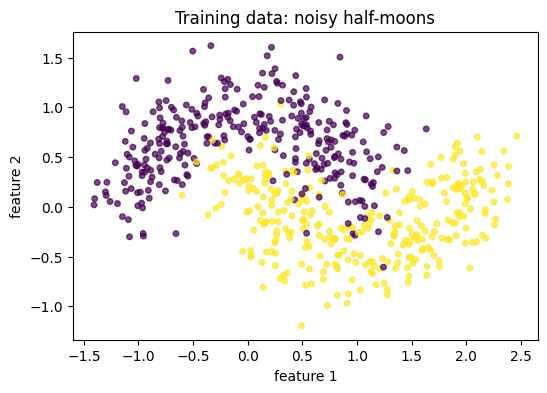

In [2]:
X, y = make_moons(n_samples=800, noise=0.25, random_state=SEED)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED
)
plt.figure(figsize=(6, 4))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, s=16, alpha=0.7)
plt.title("Training data: noisy half-moons"); plt.xlabel("feature 1"); plt.ylabel("feature 2"); plt.show()

## 6. Implement CART-style classification tree from scratch

For a node, the implementation sorts each feature, builds cumulative class counts, evaluates all distinct adjacent thresholds that respect `min_samples_leaf`, and selects the highest Gini reduction. Sorting at each node is more efficient than recomputing impurity from scratch for every possible threshold, while keeping the core mechanics readable.

The implementation uses integer-encoded classes internally and returns original class labels. It includes maximum depth, minimum split size, minimum leaf size, and a minimum impurity-decrease threshold.

In [3]:
@dataclass
class TreeNode:
    prediction: int
    n_samples: int
    impurity: float
    feature: int = -1
    threshold: float = np.nan
    left: object = None
    right: object = None
    is_leaf: bool = True
    class_counts: object = None


def gini_from_counts(counts):
    counts = np.asarray(counts, dtype=float)
    total = counts.sum()
    if total <= 0:
        return 0.0
    p = counts / total
    return float(1.0 - np.sum(p * p))


class DecisionTreeScratch:
    """Small CART-like classifier with exhaustive axis-aligned Gini splits."""
    def __init__(self, max_depth=5, min_samples_split=2, min_samples_leaf=1, min_impurity_decrease=0.0):
        if max_depth is not None and max_depth < 0:
            raise ValueError("max_depth must be nonnegative or None")
        if min_samples_split < 2 or min_samples_leaf < 1 or min_impurity_decrease < 0:
            raise ValueError("invalid stopping parameter")
        self.max_depth = max_depth
        self.min_samples_split = int(min_samples_split)
        self.min_samples_leaf = int(min_samples_leaf)
        self.min_impurity_decrease = float(min_impurity_decrease)

    def _best_split(self, X, y_encoded, parent_gini):
        n, d = X.shape
        n_classes = len(self.classes_)
        best_gain, best_feature, best_threshold = 0.0, None, None
        total_counts = np.bincount(y_encoded, minlength=n_classes)
        parent_gini = gini_from_counts(total_counts)

        for feature in range(d):
            order = np.argsort(X[:, feature], kind="mergesort")
            x_sorted = X[order, feature]
            y_sorted = y_encoded[order]
            # Boundary index i means left rows [0, ..., i].
            boundaries = np.flatnonzero(x_sorted[:-1] < x_sorted[1:])
            if len(boundaries) == 0:
                continue
            one_hot = np.eye(n_classes, dtype=np.int64)[y_sorted]
            cumulative = np.cumsum(one_hot, axis=0)
            left_sizes = boundaries + 1
            right_sizes = n - left_sizes
            eligible = (left_sizes >= self.min_samples_leaf) & (right_sizes >= self.min_samples_leaf)
            boundaries = boundaries[eligible]
            left_sizes = left_sizes[eligible]
            right_sizes = right_sizes[eligible]
            if len(boundaries) == 0:
                continue
            left_counts = cumulative[boundaries]
            right_counts = total_counts[None, :] - left_counts
            left_sq = np.sum(left_counts * left_counts, axis=1) / (left_sizes * left_sizes)
            right_sq = np.sum(right_counts * right_counts, axis=1) / (right_sizes * right_sizes)
            left_gini = 1.0 - left_sq
            right_gini = 1.0 - right_sq
            weighted = (left_sizes / n) * left_gini + (right_sizes / n) * right_gini
            gains = parent_gini - weighted
            local_idx = int(np.argmax(gains))
            gain = float(gains[local_idx])
            if gain > best_gain:
                boundary = int(boundaries[local_idx])
                threshold = x_sorted[boundary] + (x_sorted[boundary + 1] - x_sorted[boundary]) / 2.0
                best_gain, best_feature, best_threshold = gain, feature, float(threshold)
        return best_feature, best_threshold, best_gain

    def _grow(self, X, y_encoded, depth):
        counts = np.bincount(y_encoded, minlength=len(self.classes_))
        prediction = int(np.argmax(counts))
        impurity = gini_from_counts(counts)
        node = TreeNode(prediction=prediction, n_samples=len(y_encoded), impurity=impurity, class_counts=counts.copy())

        depth_limit = self.max_depth is not None and depth >= self.max_depth
        if (depth_limit or impurity <= 0.0 or len(y_encoded) < self.min_samples_split
                or len(y_encoded) < 2 * self.min_samples_leaf):
            return node

        feature, threshold, gain = self._best_split(X, y_encoded, impurity)
        if feature is None or gain < self.min_impurity_decrease or gain <= 0.0:
            return node
        left_mask = X[:, feature] <= threshold
        if left_mask.sum() < self.min_samples_leaf or (~left_mask).sum() < self.min_samples_leaf:
            return node

        node.feature = int(feature)
        node.threshold = float(threshold)
        node.left = self._grow(X[left_mask], y_encoded[left_mask], depth + 1)
        node.right = self._grow(X[~left_mask], y_encoded[~left_mask], depth + 1)
        node.is_leaf = False
        return node

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        if X.ndim != 2 or len(X) == 0 or X.shape[1] == 0:
            raise ValueError("X must be a non-empty 2D array")
        if y.ndim != 1 or len(y) != len(X):
            raise ValueError("y must be 1D with one label per row")
        if not np.isfinite(X).all():
            raise ValueError("X must contain only finite values")
        self.classes_, y_encoded = np.unique(y, return_inverse=True)
        self.n_features_in_ = X.shape[1]
        self.root_ = self._grow(X, y_encoded.astype(int), 0)
        self.n_nodes_ = self._count_nodes(self.root_)
        self.max_depth_ = self._tree_depth(self.root_)
        return self

    def _count_nodes(self, node):
        if node is None:
            return 0
        return 1 + self._count_nodes(node.left) + self._count_nodes(node.right)

    def _tree_depth(self, node):
        if node is None or node.is_leaf:
            return 0
        return 1 + max(self._tree_depth(node.left), self._tree_depth(node.right))

    def _predict_one_encoded(self, row):
        node = self.root_
        while not node.is_leaf:
            node = node.left if row[node.feature] <= node.threshold else node.right
        return node.prediction

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim != 2 or X.shape[1] != self.n_features_in_:
            raise ValueError("X must be 2D with the same feature count used during fit")
        encoded = np.fromiter((self._predict_one_encoded(row) for row in X), dtype=int, count=len(X))
        return self.classes_[encoded]

    def _predict_proba_one(self, row):
        node = self.root_
        while not node.is_leaf:
            node = node.left if row[node.feature] <= node.threshold else node.right
        # Empirical class proportions at the reached leaf.
        return node.class_counts / node.class_counts.sum()

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim != 2 or X.shape[1] != self.n_features_in_:
            raise ValueError("X must be 2D with the same feature count used during fit")
        return np.vstack([self._predict_proba_one(row) for row in X])

scratch_tree = DecisionTreeScratch(max_depth=5, min_samples_split=4, min_samples_leaf=2)
scratch_tree.fit(X_train, y_train)
scratch_pred = scratch_tree.predict(X_test)
print("Scratch accuracy:", round(accuracy_score(y_test, scratch_pred), 4))
print("Nodes:", scratch_tree.n_nodes_, "depth:", scratch_tree.max_depth_)

Scratch accuracy: 0.96
Nodes: 35 depth: 5


## 7. Visualize predictions and tree structure

The boundary is built by applying the learned tree to a grid of points. Every rectangular region corresponds to a sequence of feature-threshold decisions.

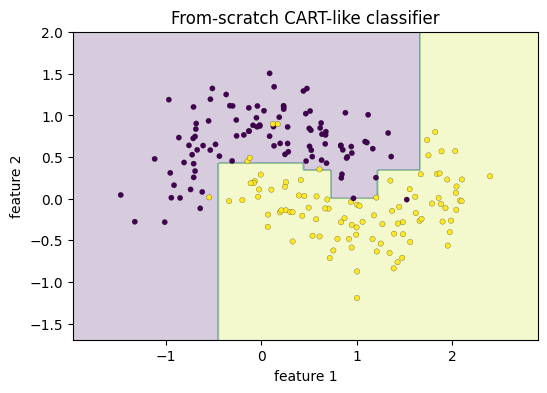

In [4]:
def plot_decision_boundary(model, X, y, title):
    x0_min, x0_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    x1_min, x1_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x0_min, x0_max, 220), np.linspace(x1_min, x1_max, 220))
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = model.predict(grid).reshape(xx.shape)
    plt.figure(figsize=(6, 4))
    plt.contourf(xx, yy, zz, alpha=0.22)
    plt.scatter(X[:, 0], X[:, 1], c=y, s=15, edgecolors="k", linewidths=0.15)
    plt.title(title); plt.xlabel("feature 1"); plt.ylabel("feature 2"); plt.show()

plot_decision_boundary(scratch_tree, X_test, y_test, "From-scratch CART-like classifier")

## 8. Compare with scikit-learn

The models need not create exactly the same tree: split tie-breaking, numerical thresholds, and implementation details can differ. Compare held-out metrics and tree size rather than demanding identical node structure.

In [5]:
sk_tree = DecisionTreeClassifier(
    criterion="gini", max_depth=5, min_samples_split=4,
    min_samples_leaf=2, random_state=SEED
).fit(X_train, y_train)
sk_pred = sk_tree.predict(X_test)
print("Scratch accuracy:", round(accuracy_score(y_test, scratch_pred), 4))
print("sklearn accuracy:", round(accuracy_score(y_test, sk_pred), 4))
print("sklearn nodes:", sk_tree.tree_.node_count, "depth:", sk_tree.get_depth())
print("Confusion matrix (sklearn):\n", confusion_matrix(y_test, sk_pred))
print(classification_report(y_test, sk_pred, digits=3))
assert accuracy_score(y_test, scratch_pred) > 0.65
assert accuracy_score(y_test, sk_pred) > 0.65
assert len(scratch_pred) == len(y_test)

Scratch accuracy: 0.96
sklearn accuracy: 0.96
sklearn nodes: 35 depth: 5
Confusion matrix (sklearn):
 [[99  1]
 [ 7 93]]
              precision    recall  f1-score   support

           0      0.934     0.990     0.961       100
           1      0.989     0.930     0.959       100

    accuracy                          0.960       200
   macro avg      0.962     0.960     0.960       200
weighted avg      0.962     0.960     0.960       200



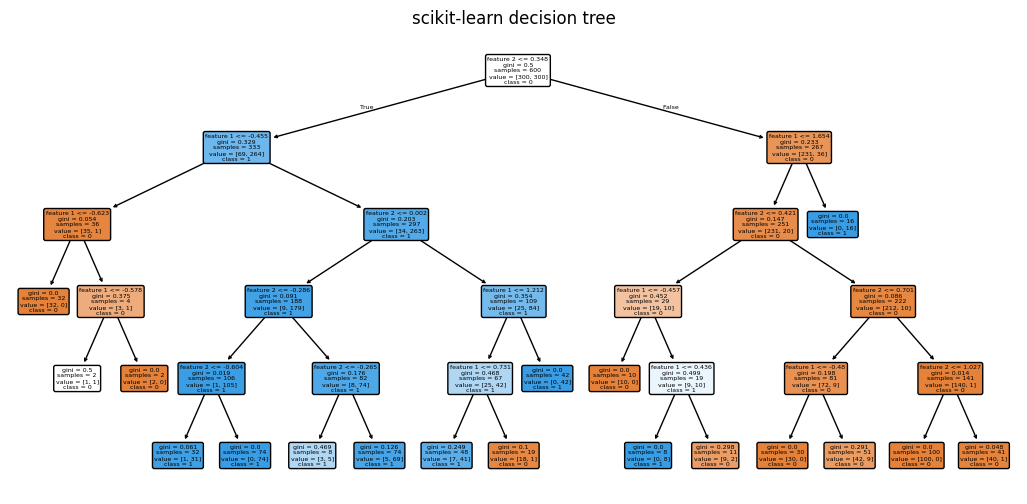

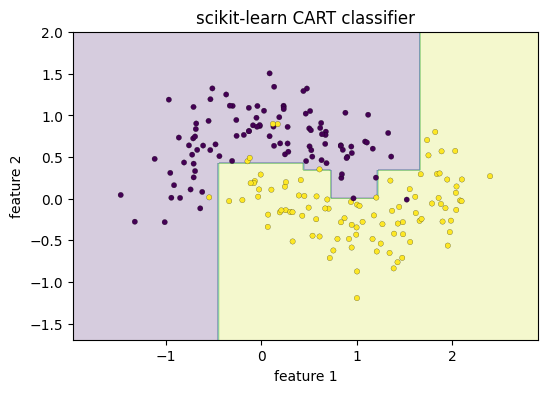

In [6]:
plt.figure(figsize=(13, 6))
plot_tree(sk_tree, filled=True, feature_names=["feature 1", "feature 2"], class_names=[str(c) for c in sk_tree.classes_], rounded=True)
plt.title("scikit-learn decision tree"); plt.show()
plot_decision_boundary(sk_tree, X_test, y_test, "scikit-learn CART classifier")

## 9. Depth controls overfitting

Train accuracy usually increases as the tree becomes more expressive; validation performance may peak and then decline. Use validation data or cross-validation to choose complexity instead of choosing the depth from training accuracy alone.

In [7]:
depth_results = []
for depth in (1, 2, 3, 4, 5, 7, None):
    clf = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=2, random_state=SEED)
    clf.fit(X_train, y_train)
    depth_results.append({
        "max_depth": depth,
        "train_accuracy": accuracy_score(y_train, clf.predict(X_train)),
        "test_accuracy": accuracy_score(y_test, clf.predict(X_test)),
        "nodes": clf.tree_.node_count,
    })
depth_results

[{'max_depth': 1, 'train_accuracy': 0.825, 'test_accuracy': 0.865, 'nodes': 3},
 {'max_depth': 2,
  'train_accuracy': 0.9083333333333333,
  'test_accuracy': 0.945,
  'nodes': 7},
 {'max_depth': 3,
  'train_accuracy': 0.9083333333333333,
  'test_accuracy': 0.945,
  'nodes': 13},
 {'max_depth': 4, 'train_accuracy': 0.91, 'test_accuracy': 0.95, 'nodes': 23},
 {'max_depth': 5, 'train_accuracy': 0.95, 'test_accuracy': 0.96, 'nodes': 35},
 {'max_depth': 7, 'train_accuracy': 0.965, 'test_accuracy': 0.95, 'nodes': 65},
 {'max_depth': None,
  'train_accuracy': 0.9766666666666667,
  'test_accuracy': 0.935,
  'nodes': 93}]

## 10. Hyperparameters and best practices

| Parameter | What it controls |
|---|---|
| `criterion` | Split quality (`gini`, `entropy`, or `log_loss` for classification in supported sklearn versions). |
| `max_depth` | Upper bound on rule-chain length; limiting depth is a direct variance control. |
| `min_samples_split` | Minimum observations needed to consider splitting a node. |
| `min_samples_leaf` | Minimum observations allowed in any leaf; often smooths predictions and improves stability. |
| `max_leaf_nodes` | Direct limit on the number of terminal regions. |
| `min_impurity_decrease` | Requires a split to improve impurity by a minimum amount. |
| `ccp_alpha` | Cost-complexity pruning strength in scikit-learn. |

Best practices: use a validation protocol to tune tree size; inspect the tree; report per-class metrics on imbalanced data; use `class_weight` when justified by the task; and consider Random Forests or boosting when single-tree instability limits quality. Trees usually do not need feature scaling, but missing-value behavior is estimator/version dependent and should be verified.

## 11. Time and space complexity

Let \(n\) be samples at a node, \(d\) features, and \(D\) the resulting tree depth.

- A naive method that recomputes every candidate partition can be as expensive as roughly \(O(dn^2)\) at a node.
- Sorting feature values and using cumulative class counts gives about \(O(dn\log n)\) work at the root. If values are re-sorted independently in each node, a balanced tree is roughly \(O(dn\log^2 n)\) across levels; a highly unbalanced tree can be substantially worse. Mature libraries use additional optimizations, so these figures describe this educational strategy, not an exact bound for every implementation.
- Inference costs \(O(D)\) threshold comparisons per observation; worst-case depth can be \(O(n)\).
- Tree storage is proportional to the number of nodes, up to \(O(n)\) nodes for a fully expanded binary tree.

The scratch implementation stores a temporary one-hot count matrix at each node, using \(O(nK)\) extra memory at that node for \(K\) classes. It is meant for learning and modest datasets, not production-scale training.

## 12. Scaling to large datasets and GPU

- Set depth/leaf constraints before optimizing hardware; a needlessly deep tree consumes time and memory.
- Use scikit-learn's optimized implementation for a single CPU tree.
- For large boosted-tree workloads, XGBoost, LightGBM, and CatBoost use algorithmic optimizations such as histogram split finding; GPU support depends on the library/version and configuration.
- Tree-building has irregular branching and data-dependent control flow, so a GPU is not automatically faster for a small standalone tree.
- Benchmark fit time, prediction latency, tree size, memory, and validation quality at realistic sample counts. Avoid allocating one-hot matrices for millions of rows in this educational implementation.

In [8]:
def benchmark_tree(n_samples, n_features=20, max_depth=10, seed=0):
    Xb, yb = make_classification(n_samples=n_samples, n_features=n_features,
                                 n_informative=min(10, n_features), n_redundant=0,
                                 random_state=seed)
    clf = DecisionTreeClassifier(max_depth=max_depth, min_samples_leaf=5, random_state=seed)
    start = time.perf_counter(); clf.fit(Xb, yb)
    fit_seconds = time.perf_counter() - start
    batch = Xb[:min(10_000, n_samples)]
    start = time.perf_counter(); clf.predict(batch)
    predict_seconds = time.perf_counter() - start
    return {"n": n_samples, "d": n_features, "fit_seconds": round(fit_seconds, 3),
            "predict_seconds_for_up_to_10k": round(predict_seconds, 4),
            "nodes": int(clf.tree_.node_count), "depth": int(clf.get_depth())}

[benchmark_tree(n) for n in (1_000, 10_000, 50_000)]

[{'n': 1000,
  'd': 20,
  'fit_seconds': 0.012,
  'predict_seconds_for_up_to_10k': 0.0002,
  'nodes': 135,
  'depth': 10},
 {'n': 10000,
  'd': 20,
  'fit_seconds': 0.189,
  'predict_seconds_for_up_to_10k': 0.001,
  'nodes': 605,
  'depth': 10},
 {'n': 50000,
  'd': 20,
  'fit_seconds': 1.088,
  'predict_seconds_for_up_to_10k': 0.001,
  'nodes': 987,
  'depth': 10}]

## 13. Correctness checks and synthesis

A classification tree is a learned sequence of threshold rules. At each step, it greedily selects a split that makes the child label distributions purer according to an impurity measure. Its flexibility is both its strength and its risk: constrain or prune the tree, and validate the result on unseen data.

In [9]:
# Determinism and edge cases
tr1 = DecisionTreeScratch(max_depth=4, min_samples_leaf=2).fit(X_train, y_train)
tr2 = DecisionTreeScratch(max_depth=4, min_samples_leaf=2).fit(X_train, y_train)
assert np.array_equal(tr1.predict(X_test), tr2.predict(X_test))
assert tr1.n_nodes_ >= 1 and tr1.max_depth_ >= 0
assert np.isin(tr1.predict(X_test), np.unique(y_train)).all()

# A pure-label dataset should stop at a single leaf.
X_pure = np.array([[0.0], [1.0], [2.0], [3.0]])
y_pure = np.array([7, 7, 7, 7])
pure_tree = DecisionTreeScratch().fit(X_pure, y_pure)
assert pure_tree.n_nodes_ == 1 and np.all(pure_tree.predict(X_pure) == 7)

try:
    DecisionTreeScratch().fit(np.array([1, 2, 3]), np.array([0, 1, 0]))
except ValueError:
    pass
else:
    raise AssertionError("Expected invalid-dimension error")
print("All decision-tree checks passed.")

All decision-tree checks passed.
